# Part 2 (Python) : Data Cleaning and EDA



In [1]:
# Upload the 3 CSV files and put them in a data/ folder (the code reads data/orders.csv etc.)
import os
os.makedirs("data", exist_ok=True)
try:
    from google.colab import files
    uploaded = files.upload()          # select customers.csv, products.csv, orders.csv
    for name in uploaded:
        os.replace(name, os.path.join("data", name))
except ImportError:
    # Not running in Colab: the CSV files must already be in a data/ folder
    print("Not running in Colab - using the CSV files in the data/ folder.")
print("Files in data/:", sorted(os.listdir("data")))

Saving orders.csv to orders.csv
Saving products.csv to products.csv
Saving customers.csv to customers.csv
Files in data/: ['customers.csv', 'orders.csv', 'products.csv']


## Setup: imports

In [2]:
# Part 2: Data cleaning and EDA (Tasks 1-10)
#
# How to run (from the main repo folder):
#     python analysis/clean_and_eda.py
#
# This script reads the raw CSV files in data/ directly with pandas.
# It does NOT use the SQL database, so Part 1 and Part 2 can run in any order.
# Every result is printed. The "Expected:" comments show the answer from the brief.
# The last step writes narrator/findings.json, which Part 3 (the narrator) reads.

import json
import os
import sqlite3

import pandas as pd

## Task 1: Load and inspect the data

In [3]:
print("========== Task 1: Load and inspect ==========")

# Read the three CSV files into DataFrames
orders = pd.read_csv("data/orders.csv")
customers = pd.read_csv("data/customers.csv")
products = pd.read_csv("data/products.csv")

# Check the size of each table (rows, columns)
# Expected: orders.shape = (180, 9)
print("orders shape   :", orders.shape)
print("customers shape:", customers.shape)
print("products shape :", products.shape)

# Look at the first 5 orders
print("\nFirst 5 rows of orders:")
print(orders.head())

# Count missing values in each column of orders
print("\nMissing values in orders:")
print(orders.isnull().sum())

========== Task 1: Load and inspect ==========
orders shape   : (180, 9)
customers shape: (45, 6)
products shape : (16, 4)

First 5 rows of orders:
  order_id customer_id product_id  order_date  quantity  discount_pct  \
0    O0001        C012        P04  2026-03-18         2          10.0   
1    O0002        C024        P06  2026-05-16         1          30.0   
2    O0003        C008        P12  2026-03-20         2           0.0   
3    O0004        C032        P03  2026-05-17         3          30.0   
4    O0005        C011        P09  2026-06-05         1          10.0   

  payment_method  rating  returned  
0            upi     2.0         0  
1            UPI     1.0         0  
2            COD     1.0         1  
3            UPI     5.0         0  
4           Card     3.0         0  

Missing values in orders:
order_id           0
customer_id        0
product_id         0
order_date         0
quantity           0
discount_pct      12
payment_method     0
rating           

## Task 2: Standardize payment_method casing

In [4]:
# The same method is typed in different ways: COD/cod, Card/card/CARD, UPI/upi
print("\n========== Task 2: Standardize payment_method ==========")

# Before cleaning: 7 different spellings
print("Before:", list(orders["payment_method"].unique()))
print("Number of distinct values before:", orders["payment_method"].nunique())

# Remove extra spaces and convert everything to UPPER CASE
orders["payment_method"] = orders["payment_method"].str.strip().str.upper()

# After cleaning: only 3 values remain
# Expected counts: CARD 70, UPI 55, COD 55
print("\nAfter:", list(orders["payment_method"].unique()))
print("Number of distinct values after:", orders["payment_method"].nunique())
print(orders["payment_method"].value_counts())


========== Task 2: Standardize payment_method ==========
Before: ['upi', 'UPI', 'COD', 'Card', 'cod', 'CARD', 'card']
Number of distinct values before: 7

After: ['UPI', 'COD', 'CARD']
Number of distinct values after: 3
payment_method
CARD    70
UPI     55
COD     55
Name: count, dtype: int64


## Task 3: Remove duplicate orders

In [5]:
# Some orders were submitted twice: same values in every column except order_id.
print("\n========== Task 3: Remove duplicates ==========")

# Columns that describe an order (everything except order_id)
key_columns = ["customer_id", "product_id", "order_date", "quantity",
               "discount_pct", "payment_method", "rating", "returned"]

# Mark a row as duplicate if the same order appeared before it (keep the first one)
is_duplicate = orders.duplicated(subset=key_columns, keep="first")

# Expected: 5 duplicates -> O0176, O0177, O0178, O0179, O0180
dropped_rows = orders[is_duplicate]
print("Number of duplicate rows:", is_duplicate.sum())
print("Dropped order_ids:", list(dropped_rows["order_id"]))

# Keep only the rows that are NOT duplicates
orders_clean = orders[~is_duplicate].copy()

# Expected shape: (175, 9)
print("Shape after removing duplicates:", orders_clean.shape)


========== Task 3: Remove duplicates ==========
Number of duplicate rows: 5
Dropped order_ids: ['O0176', 'O0177', 'O0178', 'O0179', 'O0180']
Shape after removing duplicates: (175, 9)


## Task 4: Fill missing values (on the data without duplicates)

In [6]:
print("\n========== Task 4: Fill missing values ==========")

# discount_pct: missing means no promo code was used, so fill with 0
# Expected: 12 missing
print("Missing discount_pct:", orders_clean["discount_pct"].isnull().sum())
orders_clean["discount_pct"] = orders_clean["discount_pct"].fillna(0)

# rating: find the median of the existing ratings, then fill the missing ones with it
# Expected: median = 3.0, 15 missing
rating_median = orders_clean["rating"].median()
print("Median rating:", rating_median)
print("Missing rating:", orders_clean["rating"].isnull().sum())
orders_clean["rating"] = orders_clean["rating"].fillna(rating_median)

# Check: no missing values should be left (both should be 0)
print("\nMissing values after filling:")
print(orders_clean[["discount_pct", "rating"]].isnull().sum())


========== Task 4: Fill missing values ==========
Missing discount_pct: 12
Median rating: 3.0
Missing rating: 15

Missing values after filling:
discount_pct    0
rating          0
dtype: int64


## Task 5: Merge tables and match the total with Part 1 (SQL)

In [7]:
print("\n========== Task 5: Merge and reconcile ==========")

# Join orders with products (to get price) and customers (to get city, city_tier)
merged = orders_clean.merge(products, on="product_id").merge(customers, on="customer_id")

# Value of each order after discount
merged["order_value"] = merged["quantity"] * merged["price"] * (1 - merged["discount_pct"] / 100)

# Expected: 97358.30 across 175 rows
clean_total = round(merged["order_value"].sum(), 2)
print("Merged shape:", merged.shape)
print(f"Total order value (cleaned data): Rs {clean_total:.2f}")

# Part 1 (SQL Report a) total uses the RAW data: all 180 rows, duplicates included,
# with a missing discount counted as 0% (like SQL's COALESCE).
# Calculate the same thing here from the raw rows instead of typing the number in.
# Expected: 99860.20 (same as Part 1 Report a)
raw_with_price = orders.merge(products, on="product_id")      # orders still has all 180 rows
raw_value = raw_with_price["quantity"] * raw_with_price["price"] * (1 - raw_with_price["discount_pct"].fillna(0) / 100)
part1_total = round(raw_value.sum(), 2)
difference = round(part1_total - clean_total, 2)
print(f"\nPart 1 total : {part1_total:.2f}")
print(f"Part 2 total : {clean_total:.2f}")
print(f"Difference   : {difference:.2f}")

# Check: calculate the value of the 5 dropped duplicate rows separately
dropped_with_price = dropped_rows.merge(products, on="product_id")
dropped_with_price["order_value"] = (dropped_with_price["quantity"] * dropped_with_price["price"]
                                     * (1 - dropped_with_price["discount_pct"] / 100))
dropped_total = round(dropped_with_price["order_value"].sum(), 2)
print("\nThe 5 dropped duplicate rows:")
print(dropped_with_price[["order_id", "quantity", "price", "discount_pct", "order_value"]])
print(f"Value of dropped duplicates: {dropped_total:.2f}")   # Expected: 2501.90

# Optional extra check against Part 1: if the SQL database from Part 1 exists,
# run the same total as Report (a) in SQL and compare it with our pandas number.
# If the database is not there, Skip this (Part 2 does not need Part 1 to run).
if os.path.exists("mamaearth.db"):
    connection = sqlite3.connect("mamaearth.db")
    sql_total = connection.execute(
        "SELECT ROUND(SUM(o.quantity * p.price * (1 - COALESCE(o.discount_pct, 0) / 100.0)), 2) "
        "FROM orders o JOIN products p ON o.product_id = p.product_id"
    ).fetchone()[0]
    connection.close()
    print(f"\nCheck against Part 1 database: SQL total = {sql_total:.2f}, pandas raw total = {part1_total:.2f} "
          f"-> {'MATCH' if sql_total == part1_total else 'DIFFERENT'}")
else:
    print("\nCheck against Part 1 database: skipped (mamaearth.db not found; run Part 1 first to enable it)")

# Reconciliation note
print("\nReconciliation note:")
print(f"The cleaned total (Rs {clean_total:,.2f}) is Rs {difference:,.2f} lower than the Part 1 raw "
      f"total (Rs {part1_total:,.2f}). This difference comes only from the 5 duplicate orders removed "
      f"in Task 3 ({', '.join(dropped_rows['order_id'])}). Their combined value is exactly Rs {dropped_total:,.2f}. "
      f"Filling missing values in Task 4 did not change the total: a missing discount filled with 0 "
      f"is the same as SQL's COALESCE(discount_pct, 0), and rating is not used to calculate order value.")


========== Task 5: Merge and reconcile ==========
Merged shape: (175, 18)
Total order value (cleaned data): Rs 97358.30

Part 1 total : 99860.20
Part 2 total : 97358.30
Difference   : 2501.90

The 5 dropped duplicate rows:
  order_id  quantity  price  discount_pct  order_value
0    O0176         3    599          30.0       1257.9
1    O0177         1    349          30.0        244.3
2    O0178         2    229          10.0        412.2
3    O0179         2    199          20.0        318.4
4    O0180         1    299          10.0        269.1
Value of dropped duplicates: 2501.90

Check against Part 1 database: skipped (mamaearth.db not found; run Part 1 first to enable it)

Reconciliation note:
The cleaned total (Rs 97,358.30) is Rs 2,501.90 lower than the Part 1 raw total (Rs 99,860.20). This difference comes only from the 5 duplicate orders removed in Task 3 (O0176, O0177, O0178, O0179, O0180). Their combined value is exactly Rs 2,501.90. Filling missing values in Task 4 did not

## Task 6: Find outliers in quantity using the IQR method

In [8]:
# Only FLAG the outliers with a new column. Do not delete them.
print("\n========== Task 6: IQR outliers ==========")

# Quartiles and IQR
# Expected: Q1 = 1.0, Q3 = 2.0, IQR = 1.0, lower = -0.5, upper = 3.5
Q1 = merged["quantity"].quantile(0.25)
Q3 = merged["quantity"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("Lower limit =", lower, " Upper limit =", upper)

# True if quantity is outside the limits
merged["is_outlier"] = (merged["quantity"] < lower) | (merged["quantity"] > upper)

# Expected: 2 outliers -> O0011 (quantity 25) and O0098 (quantity 30)
print("\nOutlier orders:")
print(merged[merged["is_outlier"]][["order_id", "order_date", "quantity", "order_value"]])
print("Rows still in the data:", len(merged))


========== Task 6: IQR outliers ==========
Q1 = 1.0  Q3 = 2.0  IQR = 1.0
Lower limit = -0.5  Upper limit = 3.5

Outlier orders:
   order_id  order_date  quantity  order_value
10    O0011  2026-01-28        25       7475.0
97    O0098  2026-01-10        30      10470.0
Rows still in the data: 175


## Task 7: Hypothesis - do COD orders have a higher return rate?

In [9]:
print("\n========== Task 7: COD return hypothesis ==========")
print("Hypothesis: COD (Cash on Delivery) orders are returned more often than CARD or UPI orders.")

# count = number of orders, mean = share of orders returned (returned is 0 or 1)
payment_summary = merged.groupby("payment_method")["returned"].agg(["count", "mean"])
payment_summary["return_rate_%"] = (payment_summary["mean"] * 100).round(1)
payment_summary = payment_summary.sort_values("return_rate_%", ascending=False)

# Expected: COD 44.4%, UPI 18.9%, CARD 14.7%
print(payment_summary)

cod_rate = payment_summary.loc["COD", "return_rate_%"]
card_rate = payment_summary.loc["CARD", "return_rate_%"]
upi_rate = payment_summary.loc["UPI", "return_rate_%"]
print(f"\nResult: CONFIRMED - COD return rate is {cod_rate}%, compared with "
      f"UPI {upi_rate}% and CARD {card_rate}% (about {cod_rate / card_rate:.0f}x Card).")


========== Task 7: COD return hypothesis ==========
Hypothesis: COD (Cash on Delivery) orders are returned more often than CARD or UPI orders.
                count      mean  return_rate_%
payment_method                                
COD                54  0.444444           44.4
UPI                53  0.188679           18.9
CARD               68  0.147059           14.7

Result: CONFIRMED - COD return rate is 44.4%, compared with UPI 18.9% and CARD 14.7% (about 3x Card).


## Task 8: Segmentation by payment method and city tier

In [10]:
print("\n========== Task 8: Payment method x city tier ==========")

# Return rate for every (payment_method, city_tier) combination
segment = merged.groupby(["payment_method", "city_tier"])["returned"].agg(["count", "mean"])
segment["return_rate_%"] = (segment["mean"] * 100).round(1)
print(segment)

# Find the segment with the highest return rate
# Expected: COD + Tier-2 at 54.5%
highest = segment["return_rate_%"].idxmax()
print(f"\nHighest-risk segment: {highest[0]} + Tier-{highest[1]} cities "
      f"at {segment.loc[highest, 'return_rate_%']}%")

# Compare COD in Tier-1 vs Tier-2 cities
cod_tier1 = segment.loc[("COD", 1)]
cod_tier2 = segment.loc[("COD", 2)]
print(f"COD Tier-1: {int(cod_tier1['count'])} orders, return rate {cod_tier1['return_rate_%']}%")
print(f"COD Tier-2: {int(cod_tier2['count'])} orders, return rate {cod_tier2['return_rate_%']}%")
print(f"So COD risk is not the same everywhere: it is concentrated in Tier-{highest[1]} cities.")


========== Task 8: Payment method x city tier ==========
                          count      mean  return_rate_%
payment_method city_tier                                
CARD           1             45  0.088889            8.9
               2             23  0.260870           26.1
COD            1             32  0.375000           37.5
               2             22  0.545455           54.5
UPI            1             31  0.193548           19.4
               2             22  0.181818           18.2

Highest-risk segment: COD + Tier-2 cities at 54.5%
COD Tier-1: 32 orders, return rate 37.5%
COD Tier-2: 22 orders, return rate 54.5%
So COD risk is not the same everywhere: it is concentrated in Tier-2 cities.


## Task 9: Correlation analysis

In [11]:
# Strength bands: negligible 0-0.19, weak 0.2-0.39, moderate 0.4-0.69, strong 0.7-1.0
print("\n========== Task 9: Correlation ==========")

columns = ["rating", "returned", "discount_pct", "quantity"]
corr_matrix = merged[columns].corr()
print(corr_matrix.round(3))


# Function that gives the strength band of a correlation value
def get_band(r):
    r = abs(r)
    if r < 0.2:
        return "negligible"
    elif r < 0.4:
        return "weak"
    elif r < 0.7:
        return "moderate"
    else:
        return "strong"


# Print every pair once (6 pairs). Expected: all are negligible
print("\nPairwise correlations:")
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        r = corr_matrix.loc[columns[i], columns[j]]
        print(f"{columns[i]} vs {columns[j]}: r = {r:.3f} -> {get_band(r)}")

r_discount = corr_matrix.loc["discount_pct", "returned"]
print(f"\nHypothesis 'higher discounts reduce returns': BUSTED "
      f"(r = {r_discount:.2f}, which is {get_band(r_discount)}).")


========== Task 9: Correlation ==========
              rating  returned  discount_pct  quantity
rating         1.000    -0.101         0.043    -0.098
returned      -0.101     1.000        -0.088     0.041
discount_pct   0.043    -0.088         1.000    -0.170
quantity      -0.098     0.041        -0.170     1.000

Pairwise correlations:
rating vs returned: r = -0.101 -> negligible
rating vs discount_pct: r = 0.043 -> negligible
rating vs quantity: r = -0.098 -> negligible
returned vs discount_pct: r = -0.088 -> negligible
returned vs quantity: r = 0.041 -> negligible
discount_pct vs quantity: r = -0.170 -> negligible

Hypothesis 'higher discounts reduce returns': BUSTED (r = -0.09, which is negligible).


## Task 10: Monthly revenue, with and without the outliers

In [12]:
print("\n========== Task 10: Monthly revenue ==========")

# Convert order_date to a date and take the year-month (e.g. 2026-01)
merged["order_date"] = pd.to_datetime(merged["order_date"])
merged["year_month"] = merged["order_date"].dt.strftime("%Y-%m")

# (1) Monthly revenue including the 2 outlier orders
# Expected: 2026-01 = 29582.10 is the highest month
monthly_with = merged.groupby("year_month")["order_value"].sum().round(2)
print("(1) Monthly revenue INCLUDING outliers:")
for month, value in monthly_with.items():
    print(month, f"{value:.2f}")
print("Highest month:", monthly_with.idxmax())

# (2) Monthly revenue excluding the 2 outlier orders
# Expected: 2026-03 = 20318.90 is the highest month
monthly_without = merged[merged["is_outlier"] == False].groupby("year_month")["order_value"].sum().round(2)
print("\n(2) Monthly revenue EXCLUDING outliers:")
for month, value in monthly_without.items():
    print(month, f"{value:.2f}")
print("Highest month:", monthly_without.idxmax())

# Build the conclusion from the data: which outlier orders, on which dates
outlier_rows = merged[merged["is_outlier"]]
outlier_text = " and ".join(f"{row.order_id} on {row.order_date:%Y-%m-%d}" for row in outlier_rows.itertuples())
month_with = pd.to_datetime(monthly_with.idxmax()).strftime("%B")         # e.g. January
month_without = pd.to_datetime(monthly_without.idxmax()).strftime("%B")   # e.g. March
print(f"\nConclusion: {month_with} only looks like the best month because both bulk orders were placed "
      f"in {month_with} ({outlier_text}). After removing them, "
      f"{month_without} is the real peak month. That is why we found outliers (Task 6) before this step.")


========== Task 10: Monthly revenue ==========
(1) Monthly revenue INCLUDING outliers:
2026-01 29582.10
2026-02 13195.50
2026-03 20318.90
2026-04 9495.30
2026-05 13151.10
2026-06 11615.40
Highest month: 2026-01

(2) Monthly revenue EXCLUDING outliers:
2026-01 11637.10
2026-02 13195.50
2026-03 20318.90
2026-04 9495.30
2026-05 13151.10
2026-06 11615.40
Highest month: 2026-03

Conclusion: January only looks like the best month because both bulk orders were placed in January (O0011 on 2026-01-28 and O0098 on 2026-01-10). After removing them, March is the real peak month. That is why we found outliers (Task 6) before this step.


## Final step: write the verified results to narrator/findings.json (for Part 3)

In [13]:
# Every value below is a variable calculated above - nothing is typed in by hand.
# float() / int() turn pandas numbers into plain Python numbers that JSON can save.
print("\n========== Export findings for Part 3 ==========")

peak_month = monthly_without.idxmax()            # true peak month (outliers excluded)
inflated_month = monthly_with.idxmax()           # month that only looked best because of outliers

findings = {
    "cleaned_total_revenue_inr": float(clean_total),
    "raw_total_revenue_inr": float(part1_total),
    "duplicate_reconciliation_delta_inr": float(difference),
    "return_rate_by_payment": {
        method: float(rate) for method, rate in payment_summary["return_rate_%"].items()
    },
    "highest_risk_segment": {
        "payment_method": highest[0],
        "city_tier": int(highest[1]),
        "return_rate_pct": float(segment.loc[highest, "return_rate_%"]),
    },
    "true_peak_month": {
        "month": peak_month,
        "revenue_inr": float(monthly_without[peak_month]),
    },
    "outlier_inflated_month": {
        "month": inflated_month,
        "apparent_revenue_inr": float(monthly_with[inflated_month]),
        "corrected_revenue_inr": float(monthly_without[inflated_month]),
    },
    # Extra context that helps the narrative explain the numbers above
    "extra_context": {
        "raw_order_count": int(len(orders)),
        "cleaned_order_count": int(len(orders_clean)),
        "duplicate_order_ids_removed": list(dropped_rows["order_id"]),
        "outlier_order_ids": list(outlier_rows["order_id"]),
        "cod_tier1_orders": int(cod_tier1["count"]),
        "cod_tier1_return_rate_pct": float(cod_tier1["return_rate_%"]),
        "cod_tier2_orders": int(cod_tier2["count"]),
    },
    # Where these numbers came from (shows the file was written by code)
    "_source": {
        "generated_by": "analysis/clean_and_eda.py",
        "inputs": ["data/orders.csv", "data/customers.csv", "data/products.csv"],
        "note": "Written automatically by code. Do not edit by hand - re-run the script instead.",
    },
}

os.makedirs("narrator", exist_ok=True)
with open("narrator/findings.json", "w") as f:
    json.dump(findings, f, indent=2)

print("Saved narrator/findings.json:")
print(json.dumps(findings, indent=2))


========== Export findings for Part 3 ==========
Saved narrator/findings.json:
{
  "cleaned_total_revenue_inr": 97358.3,
  "raw_total_revenue_inr": 99860.2,
  "duplicate_reconciliation_delta_inr": 2501.9,
  "return_rate_by_payment": {
    "COD": 44.4,
    "UPI": 18.9,
    "CARD": 14.7
  },
  "highest_risk_segment": {
    "payment_method": "COD",
    "city_tier": 2,
    "return_rate_pct": 54.5
  },
  "true_peak_month": {
    "month": "2026-03",
    "revenue_inr": 20318.9
  },
  "outlier_inflated_month": {
    "month": "2026-01",
    "apparent_revenue_inr": 29582.1,
    "corrected_revenue_inr": 11637.1
  },
  "extra_context": {
    "raw_order_count": 180,
    "cleaned_order_count": 175,
    "duplicate_order_ids_removed": [
      "O0176",
      "O0177",
      "O0178",
      "O0179",
      "O0180"
    ],
    "outlier_order_ids": [
      "O0011",
      "O0098"
    ],
    "cod_tier1_orders": 32,
    "cod_tier1_return_rate_pct": 37.5,
    "cod_tier2_orders": 22
  },
  "_source": {
    "gener

## Task 11: Visualizations (same code as `analysis/visualize.py`)
Both charts are saved in the `visualizations` folder and shown below.

In [14]:
# In this notebook the charts use the results from the cells above directly.

import os

import matplotlib.pyplot as plt
import pandas as pd


os.makedirs("visualizations", exist_ok=True)

### Chart 1: Return rate by payment method (bar chart)

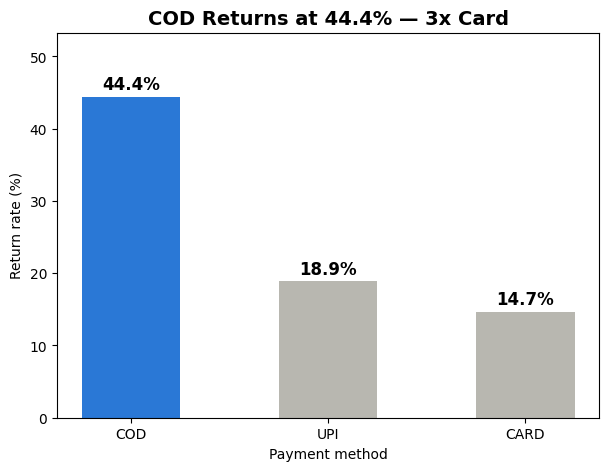


Saved visualizations/return_rate_by_payment.png


In [15]:
# payment_summary is already sorted from highest to lowest return rate (Task 7)
rates = payment_summary["return_rate_%"]
cod_rate = rates["COD"]
card_rate = rates["CARD"]

# Highlight COD in blue, other methods in grey
colors = ["#2a78d6" if method == "COD" else "#b8b7b0" for method in rates.index]

plt.figure(figsize=(7, 5))
plt.bar(rates.index, rates.values, color=colors, width=0.5)

# Write the exact percentage on top of each bar
for i, value in enumerate(rates.values):
    plt.text(i, value + 1, f"{value}%", ha="center", fontsize=12, fontweight="bold")

# Title states the finding, e.g. "COD Returns at 44.4% - 3x Card"
plt.title(f"COD Returns at {cod_rate}% — {cod_rate / card_rate:.0f}x Card", fontsize=14, fontweight="bold")
plt.xlabel("Payment method")
plt.ylabel("Return rate (%)")
plt.ylim(0, rates.max() * 1.2)
plt.savefig("visualizations/return_rate_by_payment.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved visualizations/return_rate_by_payment.png")

### Chart 2: Monthly revenue trend, outlier-corrected (line chart)

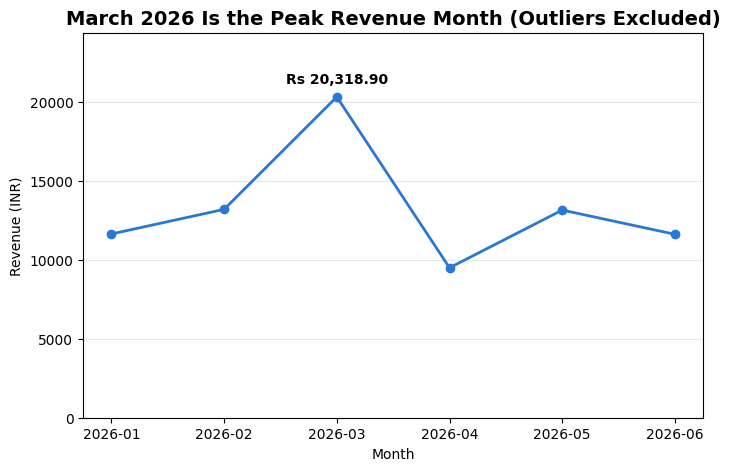

Saved visualizations/monthly_revenue_trend.png


In [16]:
# We use monthly_without (Task 10), NOT the version inflated by the 2 bulk orders
monthly = monthly_without
peak_month = monthly.idxmax()                                   # e.g. "2026-03"
peak_name = pd.to_datetime(peak_month).strftime("%B %Y")        # e.g. "March 2026"

plt.figure(figsize=(8, 5))
plt.plot(monthly.index, monthly.values, marker="o", linewidth=2, color="#2a78d6")

# Label the peak month with its value
plt.annotate(f"Rs {monthly.max():,.2f}", (peak_month, monthly.max()),
             textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")

# Title names the real peak month
plt.title(f"{peak_name} Is the Peak Revenue Month (Outliers Excluded)", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.ylim(0, monthly.max() * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.savefig("visualizations/monthly_revenue_trend.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved visualizations/monthly_revenue_trend.png")

## Download the results
Download **findings.json** (needed by the Part 3 notebook) and the two charts.

In [17]:
try:
    from google.colab import files
    files.download("narrator/findings.json")
    files.download("visualizations/return_rate_by_payment.png")
    files.download("visualizations/monthly_revenue_trend.png")
except ImportError:
    print("Saved: narrator/findings.json and the 2 charts in visualizations/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>